# SkyShield — Machine Learning Model Training and Evaluation

## SWYNEX Internship — Task 2

### Project Overview
SkyShield is an aviation safety analytics project that uses real-world
FAA Wildlife Strike data to explore wildlife strike incidents and
predict their damage severity using machine learning.

### Objectives
- Load and prepare the wildlife strike dataset.
- Select relevant features and define the prediction target.
- Train at least two machine learning models.
- Evaluate models using appropriate classification metrics.
- Compare model performance and identify the better-performing model.

### Models
1. Logistic Regression
2. Random Forest Classifier

### Evaluation Metrics
- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix


In [1]:

# Import libraries for data handling
import pandas as pd
import numpy as np

# Import visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Import machine learning utilities
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Import machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Set visualization style
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:
# Find available CSV files in the current project folder
import os
import glob

print("Current working directory:")
print(os.getcwd())

print("\nAvailable CSV files:")
csv_files = glob.glob("*.csv") + glob.glob("**/*.csv", recursive=True)

for file in sorted(set(csv_files)):
    print(file)


Current working directory:
C:\Users\vanda\SWYNX Tasks

Available CSV files:


In [3]:
import os

# List files and folders in the current directory
for item in sorted(os.listdir(".")):
    if os.path.isdir(item):
        print("FOLDER :", item)
    else:
        print("FILE   :", item)


FOLDER : .ipynb_checkpoints
FILE   : Public.xlsx
FILE   : SkyShield_Task1 (2).ipynb
FILE   : SkyShield_Task2_Model_Training_Evaluation.ipynb..ipynb


In [4]:
# Load the available Excel dataset
df = pd.read_excel("Public.xlsx")

# Display dataset dimensions
print("Dataset shape:", df.shape)

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

# Preview the first five rows
display(df.head())


Dataset shape: (358433, 102)

Column names:
['INDEX_NR', 'INCIDENT_DATE', 'INCIDENT_MONTH', 'INCIDENT_YEAR', 'TIME', 'TIME_OF_DAY', 'AIRPORT_ID', 'AIRPORT', 'LATITUDE', 'LONGITUDE', 'RUNWAY', 'STATE', 'FAAREGION', 'LOCATION', 'OPID', 'OPERATOR', 'REG', 'FLT', 'AIRCRAFT', 'AMA', 'AMO', 'EMA', 'EMO', 'AC_CLASS', 'AC_MASS', 'TYPE_ENG', 'NUM_ENGS', 'ENG_1_POS', 'ENG_2_POS', 'ENG_3_POS', 'ENG_4_POS', 'PHASE_OF_FLIGHT', 'HEIGHT', 'SPEED', 'DISTANCE', 'SKY', 'PRECIPITATION', 'AOS', 'COST_REPAIRS', 'COST_OTHER', 'COST_REPAIRS_INFL_ADJ', 'COST_OTHER_INFL_ADJ', 'INGESTED_OTHER', 'INDICATED_DAMAGE', 'DAMAGE_LEVEL', 'STR_RAD', 'DAM_RAD', 'STR_WINDSHLD', 'DAM_WINDSHLD', 'STR_NOSE', 'DAM_NOSE', 'STR_ENG1', 'DAM_ENG1', 'ING_ENG1', 'STR_ENG2', 'DAM_ENG2', 'ING_ENG2', 'STR_ENG3', 'DAM_ENG3', 'ING_ENG3', 'STR_ENG4', 'DAM_ENG4', 'ING_ENG4', 'STR_PROP', 'DAM_PROP', 'STR_WING_ROT', 'DAM_WING_ROT', 'STR_FUSE', 'DAM_FUSE', 'STR_LG', 'DAM_LG', 'STR_TAIL', 'DAM_TAIL', 'STR_LGHTS', 'DAM_LGHTS', 'STR_OTHER', 'DA

,INDEX_NR,INCIDENT_DATE,INCIDENT_MONTH,INCIDENT_YEAR,TIME,TIME_OF_DAY,AIRPORT_ID,AIRPORT,LATITUDE,LONGITUDE,...,NR_INJURIES,NR_FATALITIES,COMMENTS,IMAGE,REPORTED_NAME,REPORTED_TITLE,SOURCE,PERSON,LUPDATE,TRANSFER
0,608242,1996-06-22,6,1996,NaN,NaN,KSMF,SACRAMENTO INTL,38.69542,-121.59077,...,NaN,NaN,/Legacy Record 100001/,False,REDACTED,REDACTED,Air Transport Report,Air Transport Operations,2007-12-20,0
1,608243,1996-06-26,6,1996,NaN,NaN,KDEN,DENVER INTL AIRPORT,39.85841,-104.667,...,NaN,NaN,/Legacy Record 100002/,False,REDACTED,REDACTED,Air Transport Report,Air Transport Operations,2007-12-20,0
2,608244,1996-07-01,7,1996,NaN,NaN,KOMA,EPPLEY AIRFIELD,41.30252,-95.89417,...,NaN,NaN,/Legacy Record 100003/,False,REDACTED,REDACTED,Air Transport Report,Air Transport Operations,2007-12-20,0
3,608245,1996-07-01,7,1996,NaN,NaN,KIAD,WASHINGTON DULLES INTL ARPT,38.94453,-77.45581,...,NaN,NaN,/Legacy Record 100004/,False,REDACTED,REDACTED,Air Transport Report,Air Transport Operations,2007-12-20,0
4,608246,1996-07-01,7,1996,NaN,NaN,KLGA,LA GUARDIA ARPT,40.77724,-73.87261,...,NaN,NaN,/Legacy Record 100005/,False,REDACTED,REDACTED,Air Transport Report,Air Transport Operations,2007-12-20,0


In [5]:
# Display all column names
print("Total columns:", len(df.columns))
print("\nColumn names:")
for col in df.columns:
    print(col)

# Check for possible damage-related columns
print("\nPossible target columns:")
print([
    col for col in df.columns
    if any(word in col.lower()
           for word in ["damage", "severity", "effect", "cost"])
])


Total columns: 102

Column names:
INDEX_NR
INCIDENT_DATE
INCIDENT_MONTH
INCIDENT_YEAR
TIME
TIME_OF_DAY
AIRPORT_ID
AIRPORT
LATITUDE
LONGITUDE
RUNWAY
STATE
FAAREGION
LOCATION
OPID
OPERATOR
REG
FLT
AIRCRAFT
AMA
AMO
EMA
EMO
AC_CLASS
AC_MASS
TYPE_ENG
NUM_ENGS
ENG_1_POS
ENG_2_POS
ENG_3_POS
ENG_4_POS
PHASE_OF_FLIGHT
HEIGHT
SPEED
DISTANCE
SKY
PRECIPITATION
AOS
COST_REPAIRS
COST_OTHER
COST_REPAIRS_INFL_ADJ
COST_OTHER_INFL_ADJ
INGESTED_OTHER
INDICATED_DAMAGE
DAMAGE_LEVEL
STR_RAD
DAM_RAD
STR_WINDSHLD
DAM_WINDSHLD
STR_NOSE
DAM_NOSE
STR_ENG1
DAM_ENG1
ING_ENG1
STR_ENG2
DAM_ENG2
ING_ENG2
STR_ENG3
DAM_ENG3
ING_ENG3
STR_ENG4
DAM_ENG4
ING_ENG4
STR_PROP
DAM_PROP
STR_WING_ROT
DAM_WING_ROT
STR_FUSE
DAM_FUSE
STR_LG
DAM_LG
STR_TAIL
DAM_TAIL
STR_LGHTS
DAM_LGHTS
STR_OTHER
DAM_OTHER
OTHER_SPECIFY
EFFECT
EFFECT_OTHER
BIRD_BAND_NUMBER
SPECIES_ID
SPECIES
OUT_OF_RANGE_SPECIES
REMARKS
REMAINS_COLLECTED
REMAINS_SENT
WARNED
NUM_SEEN
NUM_STRUCK
SIZE
ENROUTE_STATE
NR_INJURIES
NR_FATALITIES
COMMENTS
IMAGE
REPORTED_NAME
R

In [8]:

# Step 3: Load the prepared SkyShield dataset

import pandas as pd

skyshield_df = pd.read_csv("SkyShield_Cleaned_Data.csv")

print("Dataset loaded successfully!")
print("Number of records:", skyshield_df.shape[0])
print("Number of columns:", skyshield_df.shape[1])

display(skyshield_df.head())


Dataset loaded successfully!
Number of records: 358433
Number of columns: 20


,INDEX_NR,INCIDENT_DATE,INCIDENT_YEAR,INCIDENT_MONTH,INCIDENT_WEEKDAY_NAME,TIME_OF_DAY,AIRPORT,STATE,AIRCRAFT,OPERATOR,PHASE_OF_FLIGHT,HEIGHT,SPEED,DISTANCE,SPECIES,NUM_STRUCK,INDICATED_DAMAGE,DAMAGE_LEVEL,COST_REPAIRS,COST_OTHER
0,608242,1996-06-22,1996,6,Saturday,NaN,SACRAMENTO INTL,CA,B-737-300,UNITED AIRLINES,Take-off Run,0.0,NaN,0.0,Unknown bird - medium,1,0,NaN,NaN,NaN
1,608243,1996-06-26,1996,6,Wednesday,NaN,DENVER INTL AIRPORT,CO,B-737-300,UNITED AIRLINES,Take-off Run,0.0,NaN,0.0,Unknown bird - medium,1,0,NaN,NaN,NaN
2,608244,1996-07-01,1996,7,Monday,NaN,EPPLEY AIRFIELD,NE,B-757-200,UNITED AIRLINES,Take-off Run,0.0,NaN,0.0,Unknown bird - medium,1,0,N,NaN,NaN
3,608245,1996-07-01,1996,7,Monday,NaN,WASHINGTON DULLES INTL ARPT,DC,A-320,UNITED AIRLINES,Approach,1000.0,NaN,NaN,Unknown bird - medium,1,0,N,NaN,NaN
4,608246,1996-07-01,1996,7,Monday,NaN,LA GUARDIA ARPT,NY,A-320,UNITED AIRLINES,Climb,5000.0,NaN,NaN,Unknown bird - medium,1,1,M,NaN,NaN


In [9]:

# Step 4: Inspect the cleaned SkyShield dataset

# Display column names and data types
print("Dataset columns and data types:")
display(
    pd.DataFrame({
        "Column": skyshield_df.columns,
        "Data Type": skyshield_df.dtypes.astype(str).values
    })
)

# Check missing values
print("\nMissing values per column:")
print(
    skyshield_df.isnull().sum()
    .sort_values(ascending=False)
)

# Check duplicate records
print("\nDuplicate rows:", skyshield_df.duplicated().sum())

# Display dataset dimensions
print("\nDataset shape:", skyshield_df.shape)


Dataset columns and data types:


,Column,Data Type
0,INDEX_NR,int64
1,INCIDENT_DATE,str
2,INCIDENT_YEAR,int64
3,INCIDENT_MONTH,int64
4,INCIDENT_WEEKDAY_NAME,str
5,TIME_OF_DAY,str
6,AIRPORT,str
7,STATE,str
8,AIRCRAFT,str
9,OPERATOR,str



Missing values per column:
COST_REPAIRS             352979
COST_OTHER               352803
SPEED                    248409
HEIGHT                   181289
TIME_OF_DAY              156605
PHASE_OF_FLIGHT          141925
DAMAGE_LEVEL             126773
DISTANCE                 120565
STATE                     48600
NUM_STRUCK                  760
OPERATOR                      2
INDEX_NR                      0
INCIDENT_MONTH                0
INCIDENT_YEAR                 0
INCIDENT_DATE                 0
INCIDENT_WEEKDAY_NAME         0
AIRCRAFT                      0
AIRPORT                       0
SPECIES                       0
INDICATED_DAMAGE              0
dtype: int64

Duplicate rows: 0

Dataset shape: (358433, 20)


In [10]:

# Step 5: Identify possible target columns

print("Available columns:")
for i, col in enumerate(skyshield_df.columns, start=1):
    print(f"{i}. {col}")

print("\nColumns related to damage or impact:")
target_candidates = [
    col for col in skyshield_df.columns
    if any(word in col.lower()
           for word in ["damage", "effect", "severity", "impact", "cost"])
]

print(target_candidates if target_candidates else "No obvious target columns found.")

# Check unique values in possible target columns
for col in target_candidates:
    print(f"\n{col} — unique values:")
    print(skyshield_df[col].value_counts(dropna=False).head(15))


Available columns:
1. INDEX_NR
2. INCIDENT_DATE
3. INCIDENT_YEAR
4. INCIDENT_MONTH
5. INCIDENT_WEEKDAY_NAME
6. TIME_OF_DAY
7. AIRPORT
8. STATE
9. AIRCRAFT
10. OPERATOR
11. PHASE_OF_FLIGHT
12. HEIGHT
13. SPEED
14. DISTANCE
15. SPECIES
16. NUM_STRUCK
17. INDICATED_DAMAGE
18. DAMAGE_LEVEL
19. COST_REPAIRS
20. COST_OTHER

Columns related to damage or impact:
['INDICATED_DAMAGE', 'DAMAGE_LEVEL', 'COST_REPAIRS', 'COST_OTHER']

INDICATED_DAMAGE — unique values:
INDICATED_DAMAGE
0    336133
1     22300
Name: count, dtype: int64

DAMAGE_LEVEL — unique values:
DAMAGE_LEVEL
N      209358
NaN    126773
M?       8985
M        8806
S        4419
D          92
Name: count, dtype: int64

COST_REPAIRS — unique values:
COST_REPAIRS
NaN         352979
5000.0         213
10000.0        209
1000.0         181
500.0          156
20000.0        155
15000.0        154
2000.0         148
50000.0        138
30000.0        119
100000.0       115
3000.0         105
25000.0        101
1500.0          89
4000.0    

In [11]:

# Step 6: Review available features and sample values

print("Dataset columns:")
print(skyshield_df.columns.tolist())

print("\nSample records:")
display(skyshield_df.head(10))

print("\nNumber of unique values per column:")
display(
    skyshield_df.nunique()
    .sort_values(ascending=True)
    .to_frame(name="Unique Values")
)


Dataset columns:
['INDEX_NR', 'INCIDENT_DATE', 'INCIDENT_YEAR', 'INCIDENT_MONTH', 'INCIDENT_WEEKDAY_NAME', 'TIME_OF_DAY', 'AIRPORT', 'STATE', 'AIRCRAFT', 'OPERATOR', 'PHASE_OF_FLIGHT', 'HEIGHT', 'SPEED', 'DISTANCE', 'SPECIES', 'NUM_STRUCK', 'INDICATED_DAMAGE', 'DAMAGE_LEVEL', 'COST_REPAIRS', 'COST_OTHER']

Sample records:


,INDEX_NR,INCIDENT_DATE,INCIDENT_YEAR,INCIDENT_MONTH,INCIDENT_WEEKDAY_NAME,TIME_OF_DAY,AIRPORT,STATE,AIRCRAFT,OPERATOR,PHASE_OF_FLIGHT,HEIGHT,SPEED,DISTANCE,SPECIES,NUM_STRUCK,INDICATED_DAMAGE,DAMAGE_LEVEL,COST_REPAIRS,COST_OTHER
0,608242,1996-06-22,1996,6,Saturday,NaN,SACRAMENTO INTL,CA,B-737-300,UNITED AIRLINES,Take-off Run,0.0,NaN,0.0,Unknown bird - medium,1,0,NaN,NaN,NaN
1,608243,1996-06-26,1996,6,Wednesday,NaN,DENVER INTL AIRPORT,CO,B-737-300,UNITED AIRLINES,Take-off Run,0.0,NaN,0.0,Unknown bird - medium,1,0,NaN,NaN,NaN
2,608244,1996-07-01,1996,7,Monday,NaN,EPPLEY AIRFIELD,NE,B-757-200,UNITED AIRLINES,Take-off Run,0.0,NaN,0.0,Unknown bird - medium,1,0,N,NaN,NaN
3,608245,1996-07-01,1996,7,Monday,NaN,WASHINGTON DULLES INTL ARPT,DC,A-320,UNITED AIRLINES,Approach,1000.0,NaN,NaN,Unknown bird - medium,1,0,N,NaN,NaN
4,608246,1996-07-01,1996,7,Monday,NaN,LA GUARDIA ARPT,NY,A-320,UNITED AIRLINES,Climb,5000.0,NaN,NaN,Unknown bird - medium,1,1,M,NaN,NaN
5,608247,1991-05-06,1991,5,Monday,Day,SAN ANTONIO INTL,TX,B-727-100,AMERICAN AIRLINES,Take-off Run,0.0,100.0,0.0,Unknown bird - medium,1,0,N,NaN,NaN
6,608249,1995-07-02,1995,7,Sunday,NaN,KANSAS CITY INTL,MO,B-737-500,UNITED AIRLINES,Landing Roll,0.0,NaN,0.0,Unknown bird - medium,1,0,N,NaN,NaN
7,608250,1990-09-19,1990,9,Wednesday,Day,DALLAS/FORT WORTH INTL ARPT,TX,MD-80,AMERICAN AIRLINES,Approach,100.0,135.0,NaN,Unknown bird - small,2-10,0,NaN,NaN,NaN
8,608251,1992-05-03,1992,5,Sunday,Day,NORMAN Y. MINETA SAN JOSE INTL ARPT,CA,MERLIN IV,WINGS WEST,Landing Roll,0.0,NaN,0.0,American robin,1,0,N,NaN,NaN
9,608254,1990-09-07,1990,9,Friday,Day,AUGUSTA REGIONAL ARPT AT BUSH FLD,GA,DC-9,UNKNOWN COMMERCIAL,Landing Roll,0.0,100.0,0.0,Unknown bird - small,2-10,0,N,NaN,NaN



Number of unique values per column:


,Unique Values
INDICATED_DAMAGE,2
TIME_OF_DAY,4
NUM_STRUCK,4
DAMAGE_LEVEL,5
INCIDENT_WEEKDAY_NAME,7
INCIDENT_MONTH,12
PHASE_OF_FLIGHT,12
INCIDENT_YEAR,37
STATE,67
DISTANCE,276


In [12]:

# Step 7: Print the dataset columns clearly

print("COLUMNS:")
print(", ".join(skyshield_df.columns.astype(str)))

print("\nFIRST 3 ROWS:")
print(skyshield_df.head(3).to_string(index=False))

print("\nUNIQUE VALUES:")
for col in skyshield_df.columns:
    print(f"{col}: {skyshield_df[col].nunique()} unique values")


COLUMNS:
INDEX_NR, INCIDENT_DATE, INCIDENT_YEAR, INCIDENT_MONTH, INCIDENT_WEEKDAY_NAME, TIME_OF_DAY, AIRPORT, STATE, AIRCRAFT, OPERATOR, PHASE_OF_FLIGHT, HEIGHT, SPEED, DISTANCE, SPECIES, NUM_STRUCK, INDICATED_DAMAGE, DAMAGE_LEVEL, COST_REPAIRS, COST_OTHER

FIRST 3 ROWS:
 INDEX_NR INCIDENT_DATE  INCIDENT_YEAR  INCIDENT_MONTH INCIDENT_WEEKDAY_NAME TIME_OF_DAY             AIRPORT STATE  AIRCRAFT        OPERATOR PHASE_OF_FLIGHT  HEIGHT  SPEED  DISTANCE               SPECIES NUM_STRUCK  INDICATED_DAMAGE DAMAGE_LEVEL  COST_REPAIRS  COST_OTHER
   608242    1996-06-22           1996               6              Saturday         NaN     SACRAMENTO INTL    CA B-737-300 UNITED AIRLINES    Take-off Run     0.0    NaN       0.0 Unknown bird - medium          1                 0          NaN           NaN         NaN
   608243    1996-06-26           1996               6             Wednesday         NaN DENVER INTL AIRPORT    CO B-737-300 UNITED AIRLINES    Take-off Run     0.0    NaN       0.0 Un

Target data type: str

Damage level counts (including missing values):
DAMAGE_LEVEL
N      209358
NaN    126773
M?       8985
M        8806
S        4419
D          92
Name: count, dtype: int64

Damage level percentages:
DAMAGE_LEVEL
N      58.41
NaN    35.37
M?      2.51
M       2.46
S       1.23
D       0.03
Name: proportion, dtype: float64

Missing target values: 126773


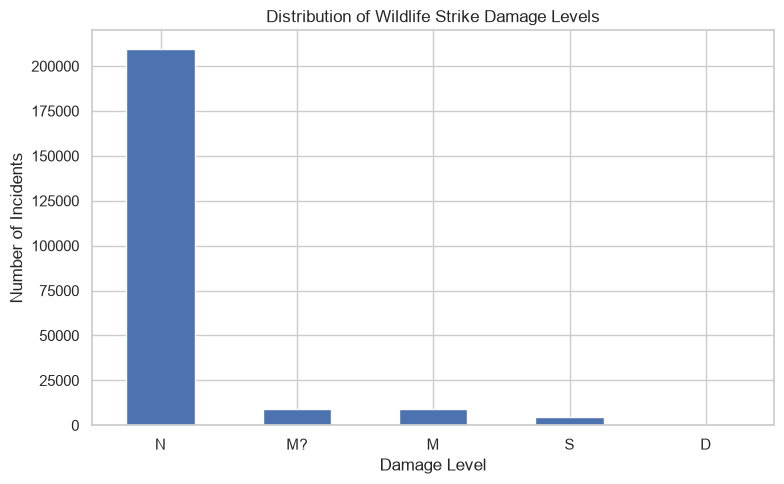

In [13]:

# Step 8: Analyze the target variable

target = "DAMAGE_LEVEL"

print("Target data type:", skyshield_df[target].dtype)

print("\nDamage level counts (including missing values):")
print(skyshield_df[target].value_counts(dropna=False))

print("\nDamage level percentages:")
print(
    (skyshield_df[target].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)

print("\nMissing target values:", skyshield_df[target].isna().sum())

# Visualize the target distribution
skyshield_df[target].value_counts().plot(
    kind="bar",
    figsize=(8, 5),
    title="Distribution of Wildlife Strike Damage Levels"
)
plt.xlabel("Damage Level")
plt.ylabel("Number of Incidents")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [14]:

# Step 9: Prepare features and target

# Remove rows where the target is missing
model_data = skyshield_df.dropna(subset=["DAMAGE_LEVEL"]).copy()

# Remove classes with fewer than 2 samples so stratified splitting is possible
class_counts = model_data["DAMAGE_LEVEL"].value_counts()
valid_classes = class_counts[class_counts >= 2].index
model_data = model_data[model_data["DAMAGE_LEVEL"].isin(valid_classes)].copy()

# Define the target variable
y = model_data["DAMAGE_LEVEL"].astype(str)

# Exclude identifiers, raw dates, and outcome-related columns
excluded_columns = [
    "INDEX_NR",
    "INCIDENT_DATE",
    "INDICATED_DAMAGE",
    "COST_REPAIRS",
    "COST_OTHER",
    "DAMAGE_LEVEL"
]

X = model_data.drop(columns=excluded_columns, errors="ignore")

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget class distribution:")
print(y.value_counts())

print("\nRemaining missing target values:", y.isna().sum())


Feature matrix shape: (231660, 14)
Target shape: (231660,)

Target class distribution:
DAMAGE_LEVEL
N     209358
M?      8985
M       8806
S       4419
D         92
Name: count, dtype: int64

Remaining missing target values: 0


In [15]:

# Step 10: Split data and build preprocessing pipeline

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

# Preprocess numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocess categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])
print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("\nTrain-test split completed successfully!")


Training records: 185328
Testing records: 46332
Numerical features: 5
Categorical features: 9

Train-test split completed successfully!


In [16]:

# Step 11: Train the Logistic Regression model

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Create the model pipeline
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train the model
logistic_model.fit(X_train, y_train)

# Generate predictions on the test set
y_pred_logistic = logistic_model.predict(X_test)

# Evaluate the model
logistic_results = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, y_pred_logistic),
    "Macro Precision": precision_score(
        y_test, y_pred_logistic,
        average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_test, y_pred_logistic,
        average="macro", zero_division=0
    ),
    "Macro F1-score": f1_score(
        y_test, y_pred_logistic,
        average="macro", zero_division=0
    )
}

print("Logistic Regression trained successfully!")
print("\nEvaluation results:")
for metric, value in logistic_results.items():
    if metric != "Model":
        print(f"{metric}: {value:.4f}")


Logistic Regression trained successfully!

Evaluation results:
Accuracy: 0.6669
Macro Precision: 0.2710
Macro Recall: 0.4327
Macro F1-score: 0.2821


In [17]:

# Step 12: Train the Random Forest model

from sklearn.ensemble import RandomForestClassifier

# Create the model pipeline
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
random_forest_model.fit(X_train, y_train)

# Generate predictions on the test set
y_pred_rf = random_forest_model.predict(X_test)

# Evaluate the model
random_forest_results = {
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y_test, y_pred_rf),
    "Macro Precision": precision_score(
        y_test, y_pred_rf,
        average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_test, y_pred_rf,
        average="macro", zero_division=0
    ),
    "Macro F1-score": f1_score(
        y_test, y_pred_rf,
        average="macro", zero_division=0
    )
}

print("Random Forest trained successfully!")
print("\nEvaluation results:")
for metric, value in random_forest_results.items():
    if metric != "Model":
        print(f"{metric}: {value:.4f}")


Random Forest trained successfully!

Evaluation results:
Accuracy: 0.5991
Macro Precision: 0.2591
Macro Recall: 0.5032
Macro F1-score: 0.2555


In [18]:
# Step 13: Compare Logistic Regression and Random Forest

results_df = pd.DataFrame([
    logistic_results,
    random_forest_results
])

# Display metrics rounded to four decimal places
metric_columns = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1-score"
]

display(
    results_df.style.format({
        col: "{:.4f}" for col in metric_columns
    })
)

# Identify the model with the highest macro F1-score
best_model_name = results_df.loc[
    results_df["Macro F1-score"].idxmax(), "Model"
]

print("\nBest model based on Macro F1-score:", best_model_name)


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-score
0,Logistic Regression,0.6669,0.2710,0.4327,0.2821
1,Random Forest,0.5991,0.2591,0.5032,0.2555



Best model based on Macro F1-score: Logistic Regression


LOGISTIC REGRESSION — CLASSIFICATION REPORT
              precision    recall  f1-score   support

           D       0.02      0.11      0.03        18
           M       0.11      0.41      0.17      1761
          M?       0.14      0.49      0.21      1797
           N       0.97      0.69      0.81     41872
           S       0.12      0.46      0.19       884

    accuracy                           0.67     46332
   macro avg       0.27      0.43      0.28     46332
weighted avg       0.89      0.67      0.75     46332


RANDOM FOREST — CLASSIFICATION REPORT
              precision    recall  f1-score   support

           D       0.01      0.56      0.02        18
           M       0.10      0.43      0.16      1761
          M?       0.14      0.47      0.21      1797
           N       0.97      0.62      0.75     41872
           S       0.07      0.45      0.13       884

    accuracy                           0.60     46332
   macro avg       0.26      0.50      0.26     

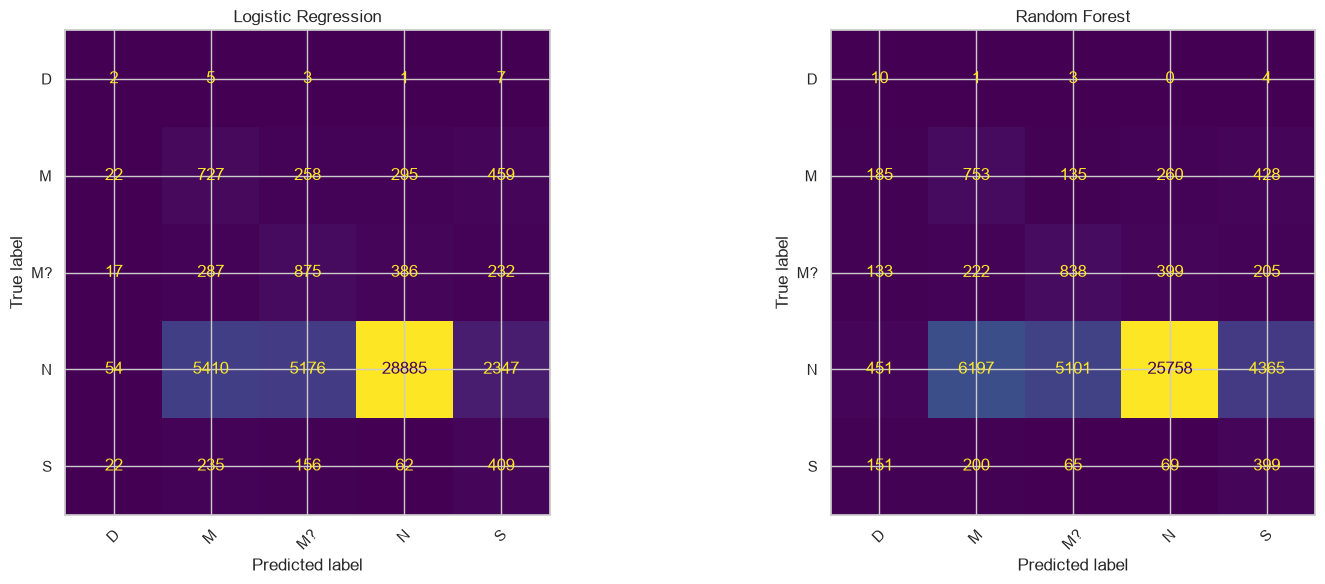

In [19]:
# Step 14: Detailed evaluation of both models

from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# Print Logistic Regression classification report
print("LOGISTIC REGRESSION — CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred_logistic,
    zero_division=0
))

# Print Random Forest classification report
print("\nRANDOM FOREST — CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred_rf,
    zero_division=0
))

# Plot confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_logistic,
    ax=axes[0],
    xticks_rotation=45,
    colorbar=False
)
axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    ax=axes[1],
    xticks_rotation=45,
    colorbar=False
)
axes[1].set_title("Random Forest")

plt.tight_layout()
plt.show()


In [20]:
# Step 15: Select the best model and save evaluation results

# Select the model with the highest macro F1-score
best_idx = results_df["Macro F1-score"].idxmax()
best_model_name = results_df.loc[best_idx, "Model"]

if best_model_name == "Logistic Regression":
    best_model = logistic_model
    best_predictions = y_pred_logistic
else:
    best_model = random_forest_model
    best_predictions = y_pred_rf

print("Selected model:", best_model_name)
print(
    "Best model Macro F1-score:",
    round(results_df.loc[best_idx, "Macro F1-score"], 4)
)

# Save the comparison table
results_df.to_csv("SkyShield_Model_Comparison.csv", index=False)

print("\nModel comparison saved to SkyShield_Model_Comparison.csv")

# Save detailed classification report
report = classification_report(
    y_test,
    best_predictions,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()
report_df.to_csv("SkyShield_Best_Model_Report.csv")

print("Best model report saved to SkyShield_Best_Model_Report.csv")


Selected model: Logistic Regression
Best model Macro F1-score: 0.2821

Model comparison saved to SkyShield_Model_Comparison.csv
Best model report saved to SkyShield_Best_Model_Report.csv


## Conclusion

Two machine learning models, Logistic Regression and Random Forest,
were trained and evaluated for predicting wildlife strike damage levels.

The models were compared using accuracy, macro precision, macro recall,
macro F1-score, classification reports, and confusion matrices.

The model with the higher macro F1-score was selected as the best
performing model in this experiment.

Macro F1-score was used because it gives equal importance to each
damage category, including less frequent classes.

The selected model's performance should be interpreted alongside its
class-wise recall and confusion matrix, particularly because missed
damage categories may be important in an aviation safety context.

### Limitations

The model's predictions depend on the available dataset and selected
features. The results demonstrate predictive performance on a held-out
test set and do not establish that the model is ready for operational
aviation safety decisions.


In [21]:
# Step 16: Save the selected trained model

import joblib

joblib.dump(best_model, "SkyShield_Best_Model.joblib")

print("Best model saved successfully!")
print("File: SkyShield_Best_Model.joblib")
print("Selected model:", best_model_name)

# List saved result files
import os

print("\nSaved output files:")
for file in [
    "SkyShield_Cleaned_Data.csv",
    "SkyShield_Model_Comparison.csv",
    "SkyShield_Best_Model_Report.csv",
    "SkyShield_Best_Model.joblib"
]:
    print(f"{file}: {'Available' if os.path.exists(file) else 'Not found'}")


Best model saved successfully!
File: SkyShield_Best_Model.joblib
Selected model: Logistic Regression

Saved output files:
SkyShield_Cleaned_Data.csv: Available
SkyShield_Model_Comparison.csv: Available
SkyShield_Best_Model_Report.csv: Available
SkyShield_Best_Model.joblib: Available
